# 04. Who should we show the campaign to?

**The question this notebook answers:** the campaign raises the visit rate on average, but is it
worth showing to everyone? If we could only reach a fraction of users, can a model pick the ones
who respond most, and does it pick better than simply targeting people who are likely to visit
anyway?

That is **uplift modelling**: predict, per user, how much *extra* visiting probability the
campaign adds. We compare:

- **Response model** (baseline): predicts who will visit, ignoring the campaign. It is *not* an
  uplift model; it targets people who visit a lot anyway.
- **S-learner**: one LightGBM model with the treatment flag as an input. Uplift is the model's
  prediction with the flag on minus off.
- **T-learner**: two LightGBM models, one fitted on treated users and one on control. Uplift is
  the difference of their predictions.

Models are fitted on the **train split**, early stopping uses the **validation split**, and
everything below is measured once on the held-out **test split**. The **Qini curve** is the
yardstick (explained where it first appears).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from expkit import config, data, nb
from expkit.qini import percentile_ci, qini_bootstrap, qini_curve
from expkit.report import MODEL_LABELS, n_, pct
from expkit.uplift import ResponseModel, SLearner, TLearner

ctx = nb.load()
R, con, st = ctx.results, ctx.con, ctx.settings
U = R["uplift"]
ctx.banner()

> Data: **Criteo Uplift v2.1**. Pipeline numbers are read from `docs/results/results.json` (written by `expkit run-all` at code commit `41db89a`) and match `docs/RESULTS.md`. Seed 42.

## 1. Fit the models and score the test split

This repeats the pipeline's fits with the same seed, so the results should reproduce
`results.json`.

In [2]:
train, val, test = (data.fetch_split(con, s) for s in ("train", "val", "test"))
models = {
    "response_model": ResponseModel(seed=st.seed),
    "s_learner": SLearner(seed=st.seed),
    "t_learner": TLearner(seed=st.seed),
}
valset = (val["X"], val["t"], val["visit"])
scores = {}
for name, m in models.items():
    t0 = time.time()
    m.fit(train["X"], train["t"], train["visit"], val=valset)
    scores[name] = m.score(test["X"])
    print(f"{MODEL_LABELS[name]}: fitted and scored in {time.time() - t0:.0f}s")

y, t = test["visit"], test["t"]
curves = {name: qini_curve(y, t, s, config.QINI_BINS) for name, s in scores.items()}
for name, c in curves.items():
    ctx.check(
        f"Qini coefficient, {name}", c.coefficient, U["test"][name]["qini_coefficient"], rtol=1e-3
    )
sel = U["selected_on_validation"]
nb.md(
    "Validation Qini coefficients (used to choose between the two uplift models): "
    + ", ".join(f"{MODEL_LABELS[k]} {v * 100:.3f}" for k, v in U["validation_qini"].items())
    + f". The **{MODEL_LABELS[sel]}** was chosen on validation; the test split was not used for that choice."
)

Response model (ignores treatment): fitted and scored in 87s


S-learner (LightGBM): fitted and scored in 112s


T-learner (LightGBM): fitted and scored in 90s


- Check: Qini coefficient, response_model: recomputed `0.00361002`, pipeline `0.00361002` (matches)

- Check: Qini coefficient, s_learner: recomputed `0.00378847`, pipeline `0.00378847` (matches)

- Check: Qini coefficient, t_learner: recomputed `0.00359272`, pipeline `0.00359272` (matches)

Validation Qini coefficients (used to choose between the two uplift models): Response model (ignores treatment) 0.340, S-learner (LightGBM) 0.344, T-learner (LightGBM) 0.327. The **S-learner (LightGBM)** was chosen on validation; the test split was not used for that choice.

## 2. Qini curves with bootstrap bands

**How to read a Qini curve.** Rank users from highest to lowest predicted uplift. For the top
*x*% of that ranking, the curve shows the estimated **extra visits per 100 users in the whole
population** if only those users were shown the campaign: it compares the visit rate of treated
and control users inside the slice, which a randomized experiment makes legitimate. The
straight dashed line is what random targeting would give, reaching the overall lift at 100%.
A model is good if its curve bows above that line. The **Qini coefficient** is the area between
the curve and the line.

Bands are 95% intervals from a Poisson bootstrap over users (the pipeline's seed and
resampling, with curves saved for plotting). All models share each resample, so differences
between them are paired.

200 bootstrap resamples in 113s


- Check: bootstrap interval low, response_model: recomputed `0.00345995`, pipeline `0.00345995` (matches)

- Check: bootstrap interval low, s_learner: recomputed `0.00364447`, pipeline `0.00364447` (matches)

- Check: bootstrap interval low, t_learner: recomputed `0.00344027`, pipeline `0.00344027` (matches)

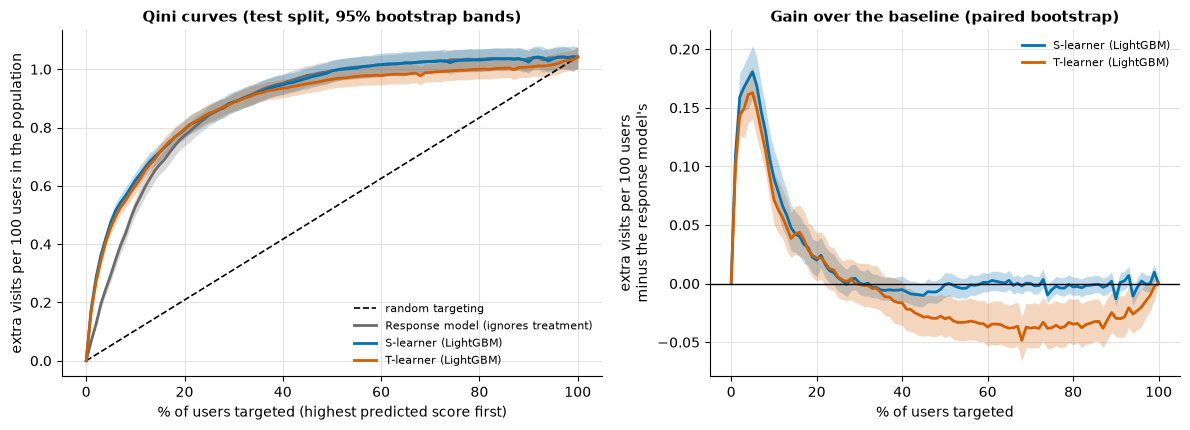

,Qini coefficient (extra visits per 100 users),95% interval,minus response model
Response model (ignores treatment),0.361,0.346 to 0.376,n/a
S-learner (LightGBM),0.379,0.364 to 0.395,+0.018 (+0.012 to +0.025)
T-learner (LightGBM),0.359,0.344 to 0.376,-0.002 (-0.015 to +0.014)


In [3]:
t0 = time.time()
boot = qini_bootstrap(
    y, t, scores, n_boot=st.n_boot, n_bins=config.QINI_BINS,
    capture_fractions=config.CAPTURE_FRACTIONS, seed=st.seed, return_curves=True,
)  # fmt: skip
print(f"{st.n_boot} bootstrap resamples in {time.time() - t0:.0f}s")
for name in scores:
    lo, hi = percentile_ci(boot[name]["coefficient"])
    ctx.check(f"bootstrap interval low, {name}", lo, U["test"][name]["qini_ci95"][0], rtol=1e-3)

ate = curves["response_model"].ate
x = curves["response_model"].x * 100
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
a.plot(x, x / 100 * ate * 100, color=nb.BLACK, ls="--", lw=1.2, label="random targeting")
for name in ("response_model", "s_learner", "t_learner"):
    q = curves[name].q * 100
    lo_b, hi_b = np.percentile(boot[name]["curve"], [2.5, 97.5], axis=0) * 100
    a.fill_between(x, lo_b, hi_b, color=nb.MODEL_COLORS[name], alpha=0.25, lw=0)
    a.plot(x, q, color=nb.MODEL_COLORS[name], lw=2, label=MODEL_LABELS[name])
a.set_xlabel("% of users targeted (highest predicted score first)")
a.set_ylabel("extra visits per 100 users in the population")
a.set_title("Qini curves (test split, 95% bootstrap bands)")
a.legend(loc="lower right", fontsize=8)

ref = boot["response_model"]["curve"]
for name in ("s_learner", "t_learner"):
    d = (boot[name]["curve"] - ref) * 100
    lo_b, hi_b = np.percentile(d, [2.5, 97.5], axis=0)
    b.fill_between(x, lo_b, hi_b, color=nb.MODEL_COLORS[name], alpha=0.25, lw=0)
    b.plot(
        x,
        (curves[name].q - curves["response_model"].q) * 100,
        color=nb.MODEL_COLORS[name],
        lw=2,
        label=MODEL_LABELS[name],
    )
b.axhline(0, color=nb.BLACK, lw=1)
b.set_xlabel("% of users targeted")
b.set_ylabel("extra visits per 100 users\nminus the response model's")
b.set_title("Gain over the baseline (paired bootstrap)")
b.legend(loc="upper right", fontsize=8)
fig.tight_layout()
ctx.savefig(fig, "uplift_qini_curves")

rows = []
for name in scores:
    r = U["test"][name]
    row = {
        "Qini coefficient (extra visits per 100 users)": f"{r['qini_coefficient'] * 100:.3f}",
        "95% interval": f"{r['qini_ci95'][0] * 100:.3f} to {r['qini_ci95'][1] * 100:.3f}",
    }
    key = "qini_minus_response_model"
    row["minus response model"] = (
        "n/a"
        if key not in r
        else f"{r[key] * 100:+.3f} ({r[key + '_ci95'][0] * 100:+.3f} to {r[key + '_ci95'][1] * 100:+.3f})"
    )
    rows.append(row)
display(pd.DataFrame(rows, index=[MODEL_LABELS[n] for n in scores]))

## 3. What share of the extra visits do we capture by targeting the top 10% or 30%?

Read straight off the Qini curves: the extra visits from the top slice divided by the extra
visits from treating everyone. The hollow diamonds repeat the calculation after re-weighting
users by inverse propensity to correct for the arm imbalance (notebook 02). If the two disagree,
the capture share is sensitive to that imbalance.

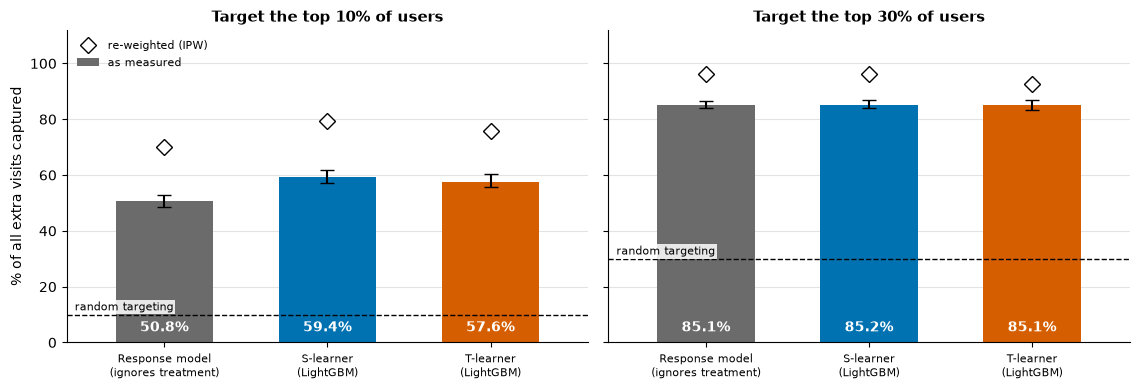

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
names = ["response_model", "s_learner", "t_learner"]
for ax, f in zip(axes, config.CAPTURE_FRACTIONS):
    for i, name in enumerate(names):
        r = U["test"][name]
        v, (lo, hi) = r[f"capture@{f}"], r[f"capture@{f}_ci95"]
        ax.bar(
            i,
            v * 100,
            color=nb.MODEL_COLORS[name],
            width=0.6,
            yerr=[[(v - lo) * 100], [(hi - v) * 100]],
            capsize=5,
            label="as measured" if i == 0 else None,
        )
        ax.text(i, 4, f"{v:.1%}", ha="center", color="white", fontsize=10, fontweight="bold")
        if U.get("test_ipw"):
            ax.plot(
                i,
                U["test_ipw"][name][f"capture@{f}"] * 100,
                "D",
                mfc="white",
                mec=nb.BLACK,
                ms=8,
                zorder=5,
                label="re-weighted (IPW)" if i == 0 else None,
            )
    ax.axhline(f * 100, color=nb.BLACK, ls="--", lw=1)
    ax.text(
        -0.55,
        f * 100 + 1.5,
        "random targeting",
        ha="left",
        fontsize=8,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1},
    )
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([MODEL_LABELS[n].replace(" (", "\n(") for n in names], fontsize=8)
    ax.set_title(f"Target the top {f:.0%} of users")
    ax.set_ylim(0, 112)
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of all extra visits captured")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
ctx.savefig(fig, "uplift_capture_shares")

## 4. Uplift by decile

Cut the test users into ten equal groups by the selected model's score (decile 1 = highest
predicted uplift). Inside each group we *measure* the uplift: treated visit rate minus control
visit rate. This uses the SQL in `sql/06_uplift_deciles.sql`. If the model works, measured
uplift should be highest in decile 1 and fall away.

- Check: decile 1 uplift: recomputed `0.0618847`, pipeline `0.0618847` (matches)

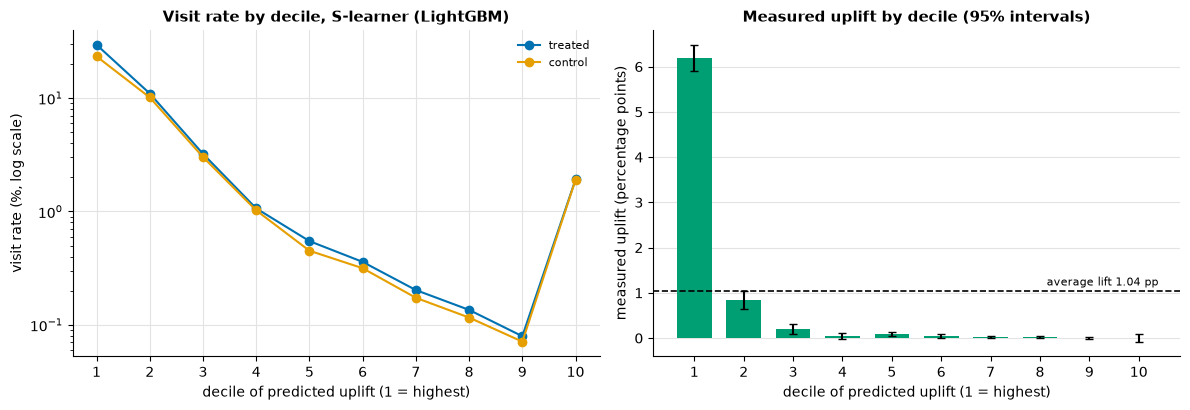

Decile 1 shows a measured uplift of **+6.19 pp**, 5.9 times the average lift of +1.04 pp. Deciles 3 to 10 average +0.06 pp. The first two deciles hold 94% of the summed decile uplifts. One oddity: decile 10 has a higher control visit rate (1.90%) than decile 9 (0.07%) while its measured uplift is +0.01 pp, so the lowest scores are not simply the least active users.

In [5]:
df = pd.DataFrame({"score": scores[sel], "treatment": t, "visit": y})
con.register("scores", df)
dec = data.run_sql(con, "06_uplift_deciles.sql")
con.unregister("scores")
ref_dec = U["deciles_selected_model"]
ctx.check("decile 1 uplift", float(dec.loc[0, "uplift"]), float(ref_dec["uplift"][0]), rtol=1e-3)

pt, pc = dec["visit_rate_treated"].to_numpy(), dec["visit_rate_control"].to_numpy()
se = np.sqrt(
    pt * (1 - pt) / dec["n_treated"].to_numpy() + pc * (1 - pc) / dec["n_control"].to_numpy()
)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
a.plot(dec["decile"], pt * 100, "-o", color=nb.TREATED, label="treated")
a.plot(dec["decile"], pc * 100, "-o", color=nb.CONTROL, label="control")
a.set_yscale("log")
a.set_xticks(range(1, 11))
a.set_xlabel("decile of predicted uplift (1 = highest)")
a.set_ylabel("visit rate (%, log scale)")
a.set_title(f"Visit rate by decile, {MODEL_LABELS[sel]}")
a.legend(fontsize=8)

upl = dec["uplift"].to_numpy() * 100
b.bar(dec["decile"], upl, yerr=1.96 * se * 100, color=nb.GREEN, capsize=3, width=0.7)
b.axhline(ate * 100, color=nb.BLACK, ls="--", lw=1.2)
b.text(10.4, ate * 100 + 0.12, f"average lift {ate * 100:.2f} pp", ha="right", fontsize=8)
b.set_xticks(range(1, 11))
b.set_xlabel("decile of predicted uplift (1 = highest)")
b.set_ylabel("measured uplift (percentage points)")
b.set_title("Measured uplift by decile (95% intervals)")
b.grid(axis="x", visible=False)
fig.tight_layout()
ctx.savefig(fig, "uplift_by_decile")
top2_share = float(upl[:2].sum() / upl.sum())
nb.md(
    f"Decile 1 shows a measured uplift of **{upl[0]:+.2f} pp**, {upl[0] / (ate * 100):.1f} times the "
    f"average lift of {ate * 100:+.2f} pp. Deciles 3 to 10 average {upl[2:].mean():+.2f} pp. The first "
    f"two deciles hold {top2_share:.0%} of the summed decile uplifts."
    + (
        f" One oddity: decile 10 has a higher control visit rate ({pc[9]:.2%}) than decile 9 "
        f"({pc[8]:.2%}) while its measured uplift is {upl[9]:+.2f} pp, so the lowest scores are not "
        f"simply the least active users."
        if pc[9] > pc[8]
        else ""
    )
)

## 5. Who is in the top 10%?

A quick profile of the users the selected model ranks highest, as the standardized difference
between their feature means and everyone else's. Features are anonymized, so this says *which*
features, not what they mean.

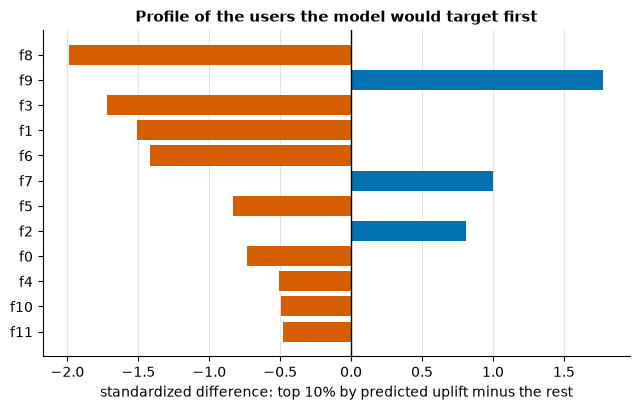

In [6]:
Xt = test["X"]
top = scores[sel] >= np.quantile(scores[sel], 0.9)
mu, sd = Xt.mean(axis=0), Xt.std(axis=0)
prof = (Xt[top].mean(axis=0) - Xt[~top].mean(axis=0)) / sd
order = np.argsort(np.abs(prof))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.barh(range(12), prof[order], color=[nb.BLUE if v > 0 else nb.VERMILLION for v in prof[order]])
ax.set_yticks(range(12))
ax.set_yticklabels([data.FEATURES[i] for i in order])
ax.axvline(0, color=nb.BLACK, lw=1)
ax.set_xlabel("standardized difference: top 10% by predicted uplift minus the rest")
ax.set_title("Profile of the users the model would target first")
ax.grid(axis="y", visible=False)
fig.tight_layout()
ctx.savefig(fig, "uplift_top_decile_profile")

## 6. Is a fancier model better? EconML causal forest

The project also fits an EconML `CausalForestDML` (a causal forest with double machine
learning). Forests are slow, so it is fitted on a subsample and compared with the other models
on one shared evaluation subset.

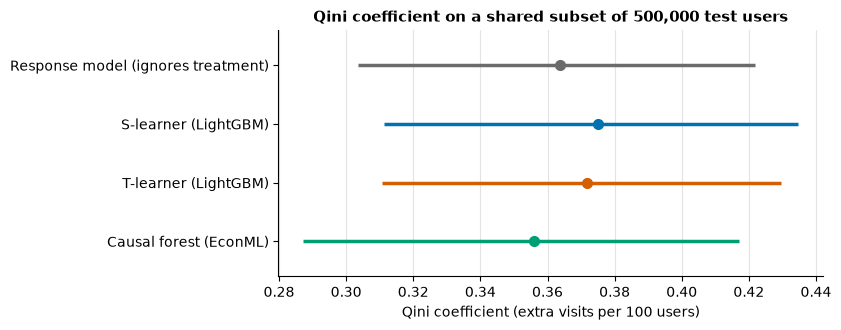

The forest was fitted on 200,000 train users (the LightGBM models used all 5,591,986), in 25 seconds. Its Qini coefficient is 0.356 (interval 0.287 to 0.417), against 0.364 for the response baseline on the same users. The intervals overlap heavily because the subset is small.

In [7]:
cf = U.get("causal_forest")
if cf:
    sub = cf["eval_subset"]
    keys = ["response_model", "s_learner", "t_learner", "causal_forest"]
    rows = [
        {
            "label": MODEL_LABELS[k],
            "est": sub[k]["qini_coefficient"],
            "lo": sub[k]["qini_ci95"][0],
            "hi": sub[k]["qini_ci95"][1],
            "color": nb.MODEL_COLORS[k],
        }
        for k in keys
    ]
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    nb.forest(ax, rows, scale=100, xlabel="Qini coefficient (extra visits per 100 users)")
    ax.set_title(f"Qini coefficient on a shared subset of {n_(cf['n_eval'])} test users")
    fig.tight_layout()
    ctx.savefig(fig, "uplift_causal_forest")
    nb.md(
        f"The forest was fitted on {n_(cf['n_train'])} train users (the LightGBM models used all "
        f"{n_(U['n_train'])}), in {cf['fit_seconds']:.0f} seconds. Its Qini coefficient is "
        f"{sub['causal_forest']['qini_coefficient'] * 100:.3f} (interval {sub['causal_forest']['qini_ci95'][0] * 100:.3f} to "
        f"{sub['causal_forest']['qini_ci95'][1] * 100:.3f}), against {sub['response_model']['qini_coefficient'] * 100:.3f} for the response "
        f"baseline on the same users. The intervals overlap heavily because the subset is small."
    )
else:
    nb.md("The EconML causal forest was not run in this configuration.")

## Summary

In [8]:
s_, t_ = U["test"]["s_learner"], U["test"]["t_learner"]
r_ = U["test"]["response_model"]
nb.notes(
    "What this means",
    [
        f"Targeting the top 10% of users ranked by the {MODEL_LABELS['s_learner']} captures "
        f"{pct(s_['capture@0.1'], 0)} of the extra visits, against {pct(r_['capture@0.1'], 0)} for ranking by likelihood to visit "
        f"and 10% for random targeting. At the top 30% the shares are {pct(s_['capture@0.3'], 0)} and {pct(r_['capture@0.3'], 0)}.",
        f"Measured uplift in the top decile is {upl[0]:+.2f} pp, against an average lift of {ate * 100:+.2f} pp"
        + (
            ", so the effect is concentrated in the users the model ranks first."
            if upl[0] > 2 * ate * 100
            else ", so the effect is not strongly concentrated in the top-ranked users."
        ),
        f"The S-learner's Qini coefficient is {s_['qini_minus_response_model'] * 100:+.3f} per 100 users above the baseline "
        f"(95% interval {s_['qini_minus_response_model_ci95'][0] * 100:+.3f} to {s_['qini_minus_response_model_ci95'][1] * 100:+.3f}); the T-learner's is "
        f"{t_['qini_minus_response_model'] * 100:+.3f} ({t_['qini_minus_response_model_ci95'][0] * 100:+.3f} to {t_['qini_minus_response_model_ci95'][1] * 100:+.3f}).",
    ],
)
ipw = U.get("test_ipw")
nb.notes(
    "What is weak",
    [
        f"The gain over the likelihood-to-visit baseline is modest in absolute terms ({s_['qini_minus_response_model'] * 100:+.3f} extra visits "
        f"per 100 users for the S-learner), and the T-learner's interval "
        + (
            "includes zero, so it is not distinguishable from the baseline."
            if t_["qini_minus_response_model_ci95"][0]
            <= 0
            <= t_["qini_minus_response_model_ci95"][1]
            else "excludes zero."
        )
        + " The baseline already captures much of the available gain.",
        (
            f"Capture shares depend on how the arms are weighted: the S-learner's top-10% share is {pct(s_['capture@0.1'], 0)} as measured and "
            f"{pct(ipw['s_learner']['capture@0.1'], 0)} after inverse-propensity re-weighting. Treat the percentages as approximate."
            if ipw
            else "Capture shares may move with arm imbalance; the re-weighted check was not run."
        ),
        "Bootstrap bands reflect sampling noise in the test users, not the randomness of model "
        "training: one seed, one train/validation/test split.",
        "Everything is measured on visits and on assignment to the campaign. There are no costs or "
        "revenue in the file, so the profit-maximizing share of users to target cannot be computed.",
        "The causal forest used a subsample, so its comparison mixes training sizes.",
    ],
)

### What this means

- Targeting the top 10% of users ranked by the S-learner (LightGBM) captures 59% of the extra visits, against 51% for ranking by likelihood to visit and 10% for random targeting. At the top 30% the shares are 85% and 85%.
- Measured uplift in the top decile is +6.19 pp, against an average lift of +1.04 pp, so the effect is concentrated in the users the model ranks first.
- The S-learner's Qini coefficient is +0.018 per 100 users above the baseline (95% interval +0.012 to +0.025); the T-learner's is -0.002 (-0.015 to +0.014).

### What is weak

- The gain over the likelihood-to-visit baseline is modest in absolute terms (+0.018 extra visits per 100 users for the S-learner), and the T-learner's interval includes zero, so it is not distinguishable from the baseline. The baseline already captures much of the available gain.
- Capture shares depend on how the arms are weighted: the S-learner's top-10% share is 59% as measured and 79% after inverse-propensity re-weighting. Treat the percentages as approximate.
- Bootstrap bands reflect sampling noise in the test users, not the randomness of model training: one seed, one train/validation/test split.
- Everything is measured on visits and on assignment to the campaign. There are no costs or revenue in the file, so the profit-maximizing share of users to target cannot be computed.
- The causal forest used a subsample, so its comparison mixes training sizes.